# Assignment 3 – Fashion-MNIST Classification

**Neural Networks – Individual Assignment**

In this notebook, I will build and compare neural networks for classifying Fashion-MNIST images, explain the methods and interpret classification errors.


---
## Dataset and Preparation

**Requirements:**
- Load the Fashion-MNIST dataset using `tf.keras.datasets.fashion_mnist.load_data()`.
- Normalize pixel values to the range **0–1**.
- Flatten the **28 × 28** images into **784** inputs (or use a Keras `Flatten` layer).
- Use the **same training and validation data** for all four models.

All models must be trained for **10 epochs** with a **batch size of 64**. Use **sparse categorical cross-entropy**, a **10-neuron softmax output layer**, and the default settings of the selected optimizer.

### Import Libraries

In [1]:
# Import the required libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

### Load the Fashion-MNIST Dataset

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


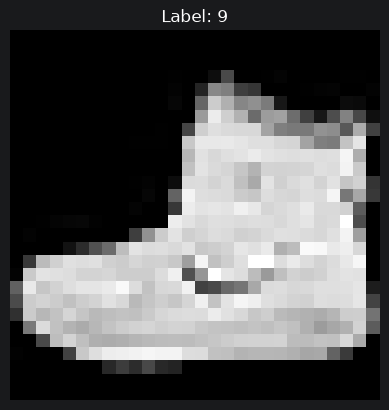

In [2]:
# Load the Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Check dataset dimensions
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

plt.imshow(x_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

### Preprocess the Data

In [3]:
# Normalize pixel values to the range [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Verify normalization
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [4]:
# Flatten 28x28 images into 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Verify the new shapes
print("Training images:", x_train.shape)
print("Test images:", x_test.shape)

Training images: (60000, 784)
Test images: (10000, 784)


In [5]:
# Split training data into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Check dataset sizes
print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

Training: (48000, 784)
Validation: (12000, 784)
Test: (10000, 784)


---
## Part A – Build and Compare Neural Networks

### Task 1 – Baseline Model

Build a baseline model with:
- **One hidden layer:** 32 neurons
- **Hidden activation:** ReLU
- **Optimizer:** Adam
- **Output layer:** 10 neurons with softmax
- **Loss:** Sparse categorical cross-entropy

Train the model for **10 epochs** with **batch size 64** and record training and validation accuracy.

In [6]:
# Build the baseline neural network
baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# Display model architecture
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the baseline model
baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
# Train the baseline model
baseline_history = baseline_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

# Store baseline results from the final epoch
baseline_train_acc = baseline_history.history["accuracy"][-1]
baseline_val_acc = baseline_history.history["val_accuracy"][-1]

print(f"Training accuracy: {baseline_train_acc:.4f}")
print(f"Validation accuracy: {baseline_val_acc:.4f}")

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7879 - loss: 0.6192 - val_accuracy: 0.8383 - val_loss: 0.4608
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8428 - loss: 0.4499 - val_accuracy: 0.8580 - val_loss: 0.4109
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8573 - loss: 0.4078 - val_accuracy: 0.8603 - val_loss: 0.4023
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8661 - loss: 0.3827 - val_accuracy: 0.8627 - val_loss: 0.3893
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8690 - loss: 0.3694 - val_accuracy: 0.8707 - val_loss: 0.3760
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8744 - loss: 0.3556 - val_accuracy: 0.8747 - val_loss: 0.3598
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8773 - loss: 0.3444 - val_accuracy: 0.8708 - val_loss: 0.3685
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8809 - loss: 0.3344 - val_accuracy: 0.

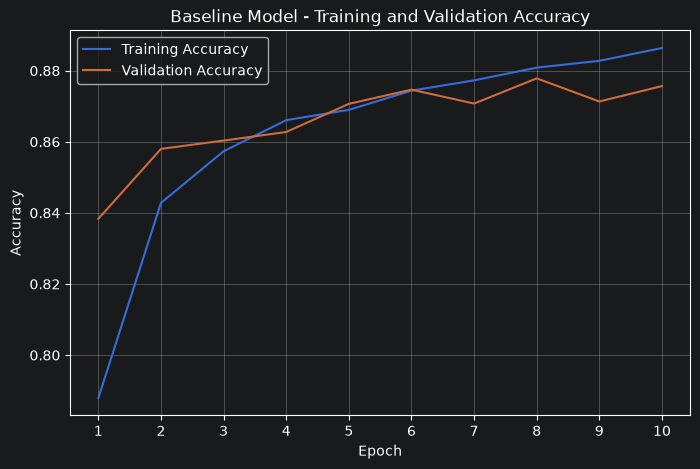

In [17]:
# Plot training and validation accuracy
epochs = range(1, len(baseline_history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, baseline_history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs, baseline_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline Model - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

### Task 2 – Change One Setting at a Time

Starting from the baseline, run three additional experiments. **Change only the specified setting** in each experiment.

| Model | Hidden neurons | Hidden activation | Optimizer |
|---|---:|---|---|
| Baseline | 32 | ReLU | Adam |
| Experiment 1 | 64 | ReLU | Adam |
| Experiment 2 | 32 | tanh | Adam |
| Experiment 3 | 32 | ReLU | SGD |

#### Experiment 1 – 64 Hidden Neurons

In [18]:
# Build Experiment 1 model with 64 hidden neurons
experiment1_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# Display model architecture
experiment1_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Compile Experiment 1 model
experiment1_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [20]:
# Train Experiment 1 model
experiment1_history = experiment1_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8037 - loss: 0.5745 - val_accuracy: 0.8454 - val_loss: 0.4398
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8518 - loss: 0.4223 - val_accuracy: 0.8655 - val_loss: 0.3852
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8630 - loss: 0.3833 - val_accuracy: 0.8691 - val_loss: 0.3743
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8718 - loss: 0.3547 - val_accuracy: 0.8772 - val_loss: 0.3497
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8774 - loss: 0.3371 - val_accuracy: 0.8746 - val_loss: 0.3485
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8825 - loss: 0.3215 - val_accuracy: 0.8832 - val_loss: 0.3349
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8874 - loss: 0.3074 - val_accuracy: 0.8775 - val_loss: 0.3535
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8915 - loss: 0.2962 - val_accuracy: 0.

In [21]:
# Store Experiment 1 results
experiment1_train_acc = experiment1_history.history["accuracy"][-1]
experiment1_val_acc = experiment1_history.history["val_accuracy"][-1]

print(f"Training accuracy: {experiment1_train_acc:.4f}")
print(f"Validation accuracy: {experiment1_val_acc:.4f}")

Training accuracy: 0.8984
Validation accuracy: 0.8888


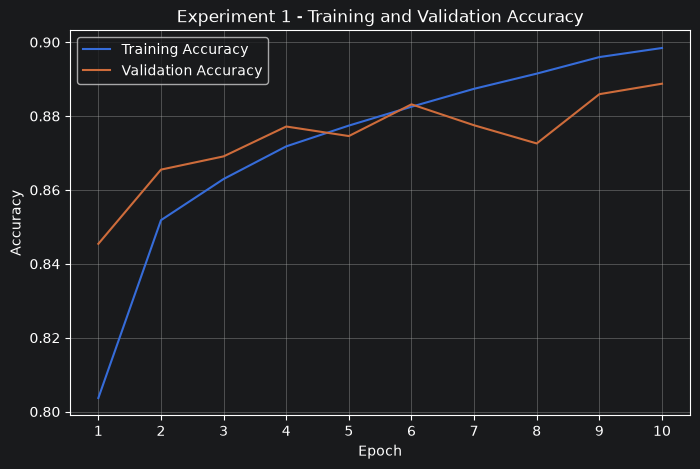

In [22]:
# Plot Experiment 1 training and validation accuracy
epochs = range(1, len(experiment1_history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, experiment1_history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs, experiment1_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Experiment 1 - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

#### Experiment 2 – tanh Activation

In [23]:
# Build Experiment 2 model with tanh activation
experiment2_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# Display model architecture
experiment2_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Compile Experiment 2 model
experiment2_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [25]:
# Train Experiment 2 model
experiment2_history = experiment2_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

# Store Experiment 2 results
experiment2_train_acc = experiment2_history.history["accuracy"][-1]
experiment2_val_acc = experiment2_history.history["val_accuracy"][-1]

print(f"Training accuracy: {experiment2_train_acc:.4f}")
print(f"Validation accuracy: {experiment2_val_acc:.4f}")

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7998 - loss: 0.6066 - val_accuracy: 0.8472 - val_loss: 0.4376
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8520 - loss: 0.4196 - val_accuracy: 0.8577 - val_loss: 0.3974
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8632 - loss: 0.3833 - val_accuracy: 0.8652 - val_loss: 0.3735
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8684 - loss: 0.3647 - val_accuracy: 0.8725 - val_loss: 0.3576
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8744 - loss: 0.3474 - val_accuracy: 0.8737 - val_loss: 0.3473
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8783 - loss: 0.3356 - val_accuracy: 0.8687 - val_loss: 0.3634
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8843 - loss: 0.3220 - val_accuracy: 0.8790 - val_loss: 0.3378
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8878 - loss: 0.3139 - val_accuracy: 0.

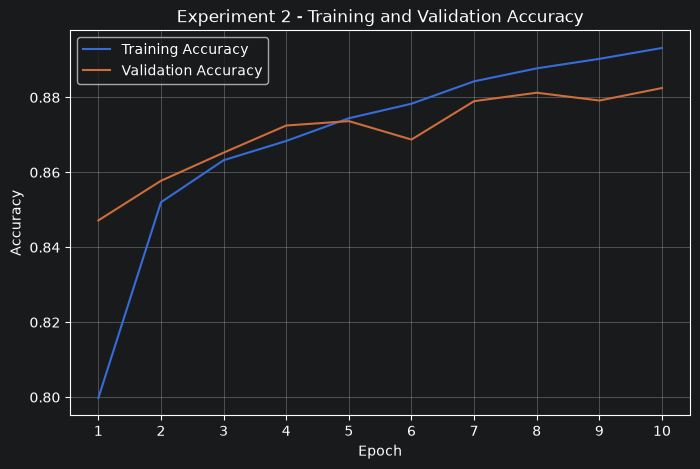

In [27]:
# Plot Experiment 2 training and validation accuracy
epochs = range(1, len(experiment2_history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, experiment2_history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs, experiment2_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Experiment 2 - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

#### Experiment 3 – SGD Optimizer

In [28]:
# Build Experiment 3 model with SGD optimizer
experiment3_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# Display model architecture
experiment3_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Compile Experiment 3 model
experiment3_model.compile(
    optimizer="sgd",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
# Train Experiment 3 model
experiment3_history = experiment3_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)
# Store Experiment 3 results
experiment3_train_acc = experiment3_history.history["accuracy"][-1]
experiment3_val_acc = experiment3_history.history["val_accuracy"][-1]

print(f"Training accuracy: {experiment3_train_acc:.4f}")
print(f"Validation accuracy: {experiment3_val_acc:.4f}")

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6659 - loss: 1.0241 - val_accuracy: 0.7645 - val_loss: 0.7141
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7796 - loss: 0.6543 - val_accuracy: 0.8026 - val_loss: 0.5933
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8071 - loss: 0.5755 - val_accuracy: 0.8163 - val_loss: 0.5407
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8194 - loss: 0.5342 - val_accuracy: 0.8269 - val_loss: 0.5097
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8268 - loss: 0.5081 - val_accuracy: 0.8344 - val_loss: 0.4870
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8328 - loss: 0.4889 - val_accuracy: 0.8360 - val_loss: 0.4726
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8370 - loss: 0.4744 - val_accuracy: 0.8419 - val_loss: 0.4555
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8411 - loss: 0.4631 - val_accuracy: 0.

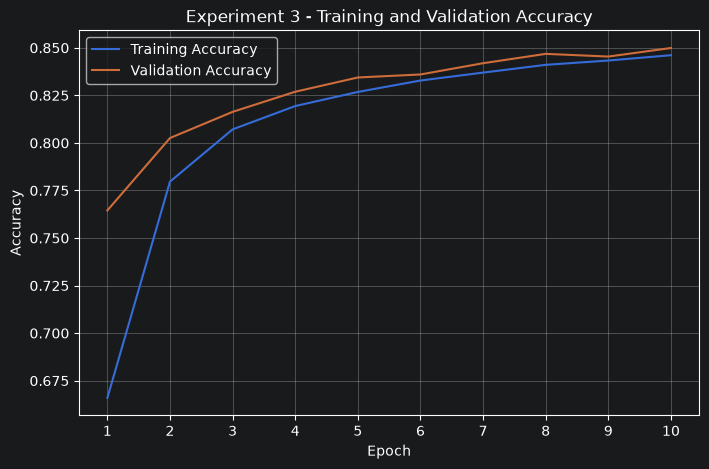

In [31]:
# Plot Experiment 3 training and validation accuracy
epochs = range(1, len(experiment3_history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, experiment3_history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs, experiment3_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Experiment 3 - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

### Task 3 – Compare Results

Record the **training accuracy** and **validation accuracy** of all four models. Select the model with the **highest validation accuracy**.

**Important:** Do not use the test set to select the best model.

In [32]:
# Create a results table for all four models
results = pd.DataFrame({
    "Model": ["Baseline", "Experiment 1", "Experiment 2", "Experiment 3"],
    "Hidden Neurons": [32, 64, 32, 32],
    "Activation": ["ReLU", "ReLU", "tanh", "ReLU"],
    "Optimizer": ["Adam", "Adam", "Adam", "SGD"],
    "Training Accuracy": [
        baseline_train_acc,
        experiment1_train_acc,
        experiment2_train_acc,
        experiment3_train_acc
    ],
    "Validation Accuracy": [
        baseline_val_acc,
        experiment1_val_acc,
        experiment2_val_acc,
        experiment3_val_acc
    ]
})

# Display results as percentages
display(
    results.style.format({
        "Training Accuracy": "{:.2%}",
        "Validation Accuracy": "{:.2%}"
    })
)

,Model,Hidden Neurons,Activation,Optimizer,Training Accuracy,Validation Accuracy
0,Baseline,32,ReLU,Adam,88.64%,87.57%
1,Experiment 1,64,ReLU,Adam,89.84%,88.88%
2,Experiment 2,32,tanh,Adam,89.32%,88.25%
3,Experiment 3,32,ReLU,SGD,84.61%,84.99%


In [33]:
# Find the model with the highest validation accuracy
best_index = results["Validation Accuracy"].idxmax()

best_model_name = results.loc[best_index, "Model"]
best_val_acc = results.loc[best_index, "Validation Accuracy"]

print(f"Best model: {best_model_name}")
print(f"Validation accuracy: {best_val_acc:.2%}")

Best model: Experiment 1
Validation accuracy: 88.88%


**Selected model:** [Write which model had the highest validation accuracy]

**Reason for selection:** [Briefly explain your choice based on validation accuracy]

### Evaluate the Selected Model on the Test Set

In [34]:
# Select the best model based on validation accuracy
models = {
    "Baseline": baseline_model,
    "Experiment 1": experiment1_model,
    "Experiment 2": experiment2_model,
    "Experiment 3": experiment3_model
}

best_model = models[best_model_name]

# Evaluate the selected model on the test dataset
test_loss, test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Selected model: {best_model_name}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Selected model: Experiment 1
Test loss: 0.3549
Test accuracy: 87.29%


**Test accuracy of selected model:** [Insert your measured test accuracy]

---
## Part B – Explain Your Neural Network

Answer Q1–Q4 in your own words. Keep each answer brief (approximately **3–5 sentences per question**, apart from calculations).

### Q1 – Architecture and Parameters

**Question:** For the baseline model (784 inputs, 32 hidden neurons and 10 outputs), calculate the number of trainable weights and biases. Explain the difference between a parameter and a hyperparameter.

**Calculations:**

The baseline model consists of 784 input features, 32 neurons in the hidden layer, and 10 output neurons.

Hidden layer:

\begin{aligned}
\text{Weights} &= 784 \times 32 = 25\,088\\
\text{Biases} &= 32
\end{aligned}


Output layer:

\begin{aligned}
\text{Weights} &= 32 \times 10 = 320\\
\text{Biases} &= 10
\end{aligned}


Total trainable parameters:
\[
25\,088 + 32 + 320 + 10 = 25\,450
\]

**Answer:**

A parameter is a value, such as a weight or bias, that the neural network learns and updates during training. A hyperparameter is a setting chosen before training, such as the number of hidden neurons, learning rate, batch size, or number of epochs. Unlike parameters, hyperparameters are not automatically learned through backpropagation.

### Q2 – Activation and Loss

**Question:** Why do we use ReLU in the hidden layer and softmax in the output layer? Why is sparse categorical cross-entropy appropriate for this dataset?

**Answer:**

ReLU is used in the hidden layer to introduce non-linearity, allowing the neural network to learn more complex patterns in the images. Softmax is used in the output layer to convert the outputs into probabilities for the 10 clothing categories, where all probabilities sum to 1. Sparse categorical cross-entropy is an appropriate loss function because Fashion-MNIST is a multi-class classification problem where each image has a single integer label from 0 to 9. The loss function measures how well the predicted probabilities match the correct labels during training.

### Q3 – Training and Keras Functions

**Question:** Explain the purposes of `model.compile()`, `model.fit()`, `model.evaluate()` and `model.predict()`. Briefly explain what backpropagation and the optimizer do during training.

**Answer:**

The model.compile() function configures the neural network by specifying the optimizer, loss function, and evaluation metrics. The model.fit() function trains the model using the training data, while model.evaluate() measures its performance on a dataset using metrics such as loss and accuracy. The model.predict() function generates predictions for new input data. During training, backpropagation calculates the gradients of the loss with respect to the model's weights and biases. The optimizer then uses these gradients to update the parameters in order to minimize the loss and improve the model's performance.

### Q4 – Interpreting Your Experiments

**Question:** Which model achieved the highest validation accuracy? Did changing the number of neurons, activation function or optimizer always improve accuracy? Explain using your results.

**Answer:**

Experiment 1 achieved the highest validation accuracy of 88.88%, using 64 hidden neurons, ReLU activation, and the Adam optimizer. Increasing the number of hidden neurons from 32 to 64 improved validation accuracy from 87.57% to 88.88%. Changing the activation function from ReLU to tanh also improved validation accuracy slightly, reaching 88.25%. However, replacing Adam with SGD reduced validation accuracy to 84.99%, showing that changing model settings does not always improve performance. These results suggest that increasing the number of neurons was the most effective change among the three experiments.

---
## Part C – Understand Classification Errors

Generate a **confusion matrix** for your selected model using the **test data**. Identify one pair of clothing categories the model confuses.

Explain in **2–3 sentences** what the confusion matrix shows that overall accuracy does not.

### Predictions on the Test Set

In [35]:
# Predict clothing categories using the selected model
y_pred_prob = best_model.predict(x_test)

# Convert predicted probabilities to class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Check the predictions
print("Predicted labels:", y_pred[:10])
print("Actual labels:", y_test[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Predicted labels: [9 2 1 1 6 1 4 6 5 7]
Actual labels: [9 2 1 1 6 1 4 6 5 7]


### Confusion Matrix

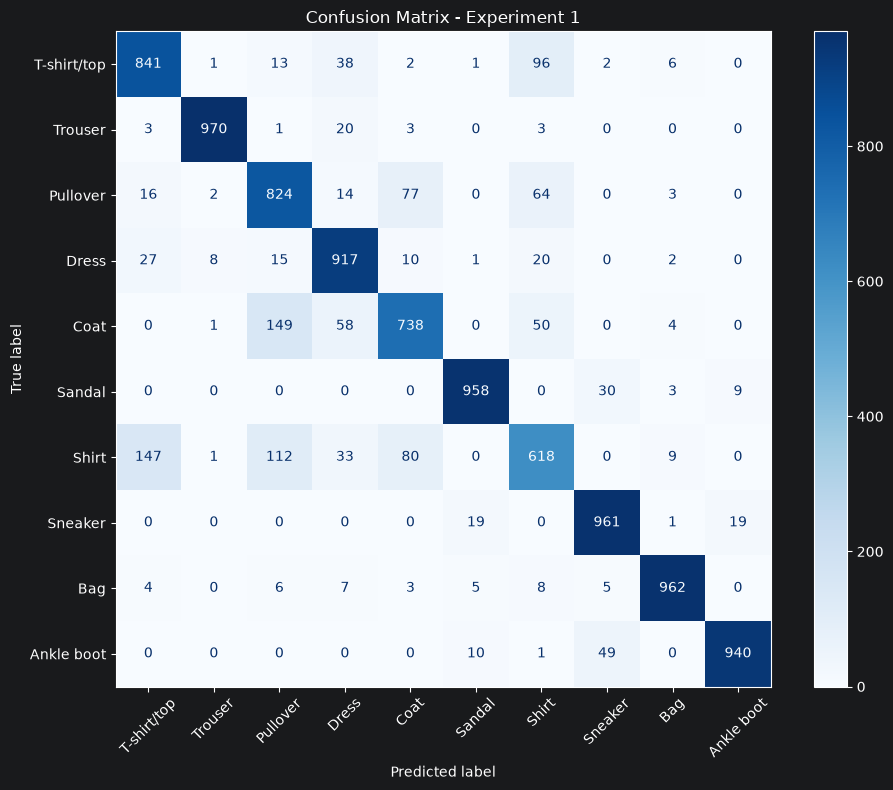

In [36]:
# Fashion-MNIST class names
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", ax=ax, xticks_rotation=45, values_format="d")

plt.title("Confusion Matrix - Experiment 1")
plt.tight_layout()
plt.show()

### Interpretation

**Two clothing categories the model confuses:** [Category 1] and [Category 2]

**Answer (2–3 sentences):**

The confusion matrix shows that the model frequently confuses Shirt and T-shirt/top, misclassifying 147 Shirt images as T-shirt/top and 96 T-shirt/top images as Shirt. While the overall test accuracy of 87.29% indicates how often the model makes correct predictions, the confusion matrix provides a more detailed view of which categories are misclassified. This helps identify specific weaknesses in the model, particularly when distinguishing between visually similar clothing categories.